In [1]:
import pandas as pd

df = pd.read_csv("../Dataset/StudentPerformanceFactors.csv")

df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [2]:
print("Dataset Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

Dataset Shape: (6607, 20)

Columns:
['Hours_Studied', 'Attendance', 'Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours', 'Previous_Scores', 'Motivation_Level', 'Internet_Access', 'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender', 'Exam_Score']


In [3]:
print("Data Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Data Types:
Hours_Studied                 int64
Attendance                    int64
Parental_Involvement            str
Access_to_Resources             str
Extracurricular_Activities      str
Sleep_Hours                   int64
Previous_Scores               int64
Motivation_Level                str
Internet_Access                 str
Tutoring_Sessions             int64
Family_Income                   str
Teacher_Quality                 str
School_Type                     str
Peer_Influence                  str
Physical_Activity             int64
Learning_Disabilities           str
Parental_Education_Level        str
Distance_from_Home              str
Gender                          str
Exam_Score                    int64
dtype: object

Missing Values:
Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motiva

In [4]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 235


In [5]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

print(missing_values)

Teacher_Quality             78
Parental_Education_Level    90
Distance_from_Home          67
dtype: int64


In [6]:
categorical_columns = [
    "Teacher_Quality",
    "Parental_Education_Level",
    "Distance_from_Home"
]

for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after cleaning:")
print(df.isnull().sum().sum())

Missing values after cleaning:
0


In [7]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n{col}:")
    print(df[col].unique())


Parental_Involvement:
<StringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str

Access_to_Resources:
<StringArray>
['High', 'Medium', 'Low']
Length: 3, dtype: str

Extracurricular_Activities:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

Motivation_Level:
<StringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str

Internet_Access:
<StringArray>
['Yes', 'No']
Length: 2, dtype: str

Family_Income:
<StringArray>
['Low', 'Medium', 'High']
Length: 3, dtype: str

Teacher_Quality:
<StringArray>
['Medium', 'High', 'Low']
Length: 3, dtype: str

School_Type:
<StringArray>
['Public', 'Private']
Length: 2, dtype: str

Peer_Influence:
<StringArray>
['Positive', 'Negative', 'Neutral']
Length: 3, dtype: str

Learning_Disabilities:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

Parental_Education_Level:
<StringArray>
['High School', 'College', 'Postgraduate']
Length: 3, dtype: str

Distance_from_Home:
<StringArray>
['Near', 'Moderate', 'Far']
Length: 3, dtype: str

Gender:
<StringArr

/var/folders/4w/6gp6gmg50_5fczzk0p7f3qpw0000gn/T/ipykernel_5894/4033208276.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


In [8]:
categorical_columns = df.select_dtypes(include=["str"]).columns

In [9]:
numeric_columns = [
    "Hours_Studied",
    "Attendance",
    "Sleep_Hours",
    "Previous_Scores",
    "Tutoring_Sessions",
    "Physical_Activity",
    "Exam_Score"
]

df[numeric_columns].describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [10]:
df[df["Exam_Score"] > 100]

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
1525,27,98,Low,Medium,Yes,6,93,Low,No,5,High,High,Public,Positive,3,No,High School,Moderate,Female,101


In [11]:
df.loc[df["Exam_Score"] > 100, "Exam_Score"] = 100

print("Maximum Exam Score:", df["Exam_Score"].max())

Maximum Exam Score: 100


In [12]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Dataset shape:", df.shape)

Missing values: 0
Duplicate rows: 0
Dataset shape: (6607, 20)


In [13]:
print("Average Exam Score:", df["Exam_Score"].mean())
print("Highest Exam Score:", df["Exam_Score"].max())
print("Lowest Exam Score:", df["Exam_Score"].min())
print("Median Exam Score:", df["Exam_Score"].median())

Average Exam Score: 67.23550779476312
Highest Exam Score: 100
Lowest Exam Score: 55
Median Exam Score: 67.0


In [14]:
study_hours_analysis = df.groupby("Hours_Studied")["Exam_Score"].mean()

study_hours_analysis

Hours_Studied
1     71.000000
2     63.000000
3     61.333333
4     61.647059
5     62.857143
6     63.470588
7     64.352941
8     64.155172
9     64.162791
10    64.393617
11    64.979452
12    64.765625
13    64.724771
14    65.576208
15    65.590476
16    66.182336
17    66.328084
18    67.042394
19    66.959184
20    66.950538
21    67.682135
22    67.480100
23    68.180049
24    68.187675
25    68.847751
26    68.665399
27    69.458515
28    69.608187
29    70.283582
30    70.617886
31    70.688312
32    70.944444
33    70.025000
34    70.724138
35    71.800000
36    71.181818
37    73.333333
38    72.714286
39    74.714286
43    78.000000
44    71.000000
Name: Exam_Score, dtype: float64

In [16]:
plt.figure(figsize=(10, 5))

study_hours_analysis.plot(kind="line", marker="o")

plt.title("Average Exam Score by Hours Studied")
plt.xlabel("Hours Studied")
plt.ylabel("Average Exam Score")
plt.grid(True)
plt.tight_layout()

plt.show()

NameError: name 'plt' is not defined

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

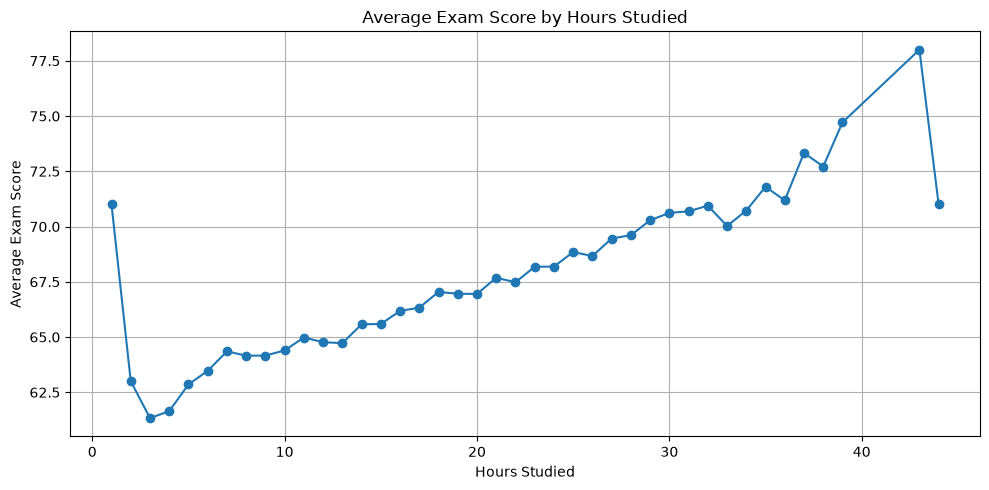

In [18]:
plt.figure(figsize=(10, 5))

study_hours_analysis.plot(kind="line", marker="o")

plt.title("Average Exam Score by Hours Studied")
plt.xlabel("Hours Studied")
plt.ylabel("Average Exam Score")
plt.grid(True)
plt.tight_layout()

plt.show()

In [19]:
attendance_analysis = df.groupby("Attendance")["Exam_Score"].mean()

attendance_analysis

Attendance
60     62.413793
61     63.384146
62     63.756579
63     64.361290
64     63.884615
65     63.905063
66     64.537931
67     64.626316
68     65.147059
69     65.123529
70     65.527950
71     65.611111
72     65.694611
73     65.952381
74     66.272727
75     66.288591
76     66.886486
77     66.668478
78     66.890909
79     66.828571
80     67.088757
81     67.232143
82     67.341040
83     67.968153
84     67.742857
85     67.883562
86     68.655629
87     68.741722
88     68.909677
89     69.104938
90     70.012821
91     69.417143
92     69.727273
93     69.820359
94     69.588889
95     70.067485
96     70.571429
97     70.378882
98     70.679144
99     70.889610
100    70.765432
Name: Exam_Score, dtype: float64

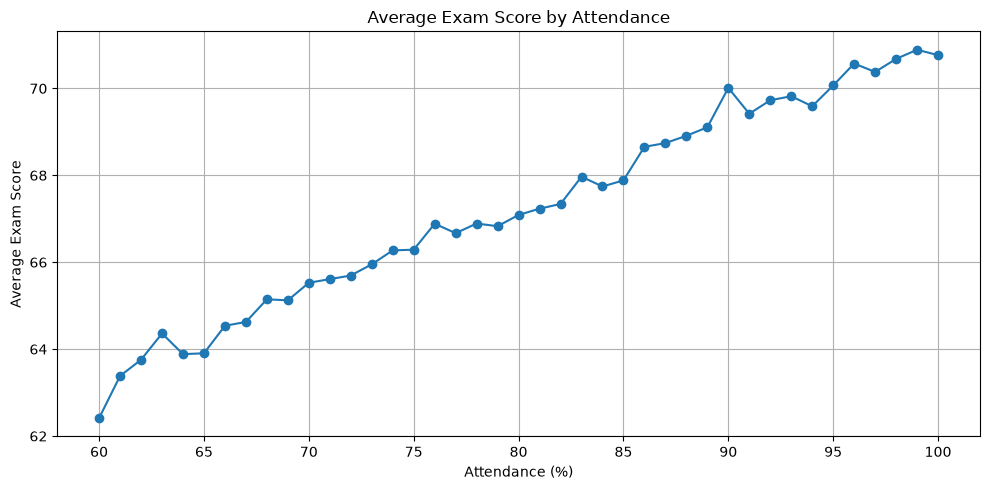

In [20]:
plt.figure(figsize=(10, 5))

attendance_analysis.plot(kind="line", marker="o")

plt.title("Average Exam Score by Attendance")
plt.xlabel("Attendance (%)")
plt.ylabel("Average Exam Score")
plt.grid(True)
plt.tight_layout()

plt.show()

In [21]:
previous_score_analysis = df.groupby("Previous_Scores")["Exam_Score"].mean()

previous_score_analysis

Previous_Scores
50     65.516129
51     65.912698
52     66.875000
53     66.270833
54     66.220588
55     66.096774
56     66.416667
57     66.872000
58     66.641667
59     66.626761
60     66.719008
61     66.788618
62     66.387097
63     66.274074
64     66.469697
65     66.235294
66     66.945455
67     66.776119
68     66.924242
69     67.255814
70     66.867647
71     66.780822
72     67.150000
73     66.905797
74     66.925373
75     67.204545
76     67.957143
77     67.680328
78     67.084615
79     67.250000
80     67.360902
81     67.096774
82     67.085106
83     67.264000
84     67.900826
85     67.266667
86     67.795620
87     67.709677
88     68.043165
89     67.692308
90     68.121951
91     68.286765
92     67.928571
93     68.674419
94     68.316129
95     68.627907
96     68.614379
97     68.504348
98     67.870229
99     67.984000
100    68.391304
Name: Exam_Score, dtype: float64

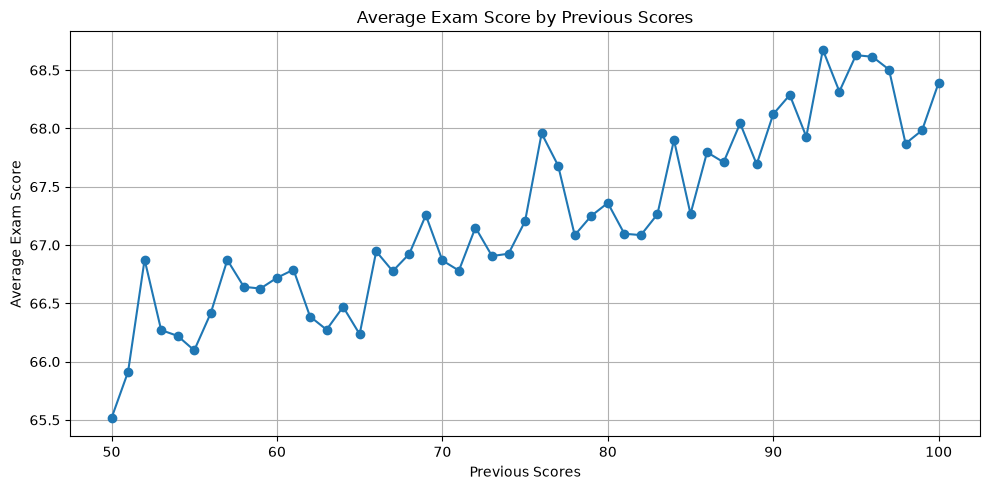

In [22]:
plt.figure(figsize=(10, 5))

previous_score_analysis.plot(kind="line", marker="o")

plt.title("Average Exam Score by Previous Scores")
plt.xlabel("Previous Scores")
plt.ylabel("Average Exam Score")
plt.grid(True)
plt.tight_layout()

plt.show()

In [23]:
motivation_analysis = df.groupby("Motivation_Level")["Exam_Score"].mean().sort_values()

motivation_analysis

Motivation_Level
Low       66.751678
Medium    67.330648
High      67.704321
Name: Exam_Score, dtype: float64

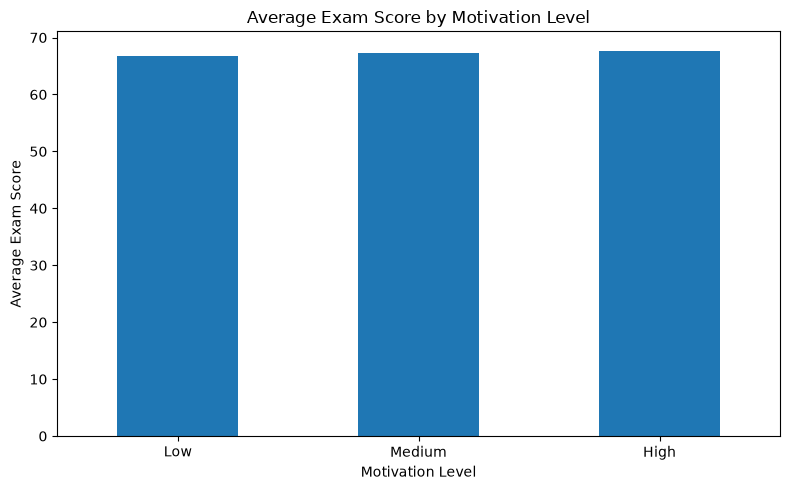

In [24]:
plt.figure(figsize=(8, 5))

motivation_analysis.plot(kind="bar")

plt.title("Average Exam Score by Motivation Level")
plt.xlabel("Motivation Level")
plt.ylabel("Average Exam Score")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [25]:
parental_analysis = df.groupby("Parental_Involvement")["Exam_Score"].mean().sort_values()

parental_analysis

Parental_Involvement
Low       66.357517
Medium    67.098156
High      68.092767
Name: Exam_Score, dtype: float64

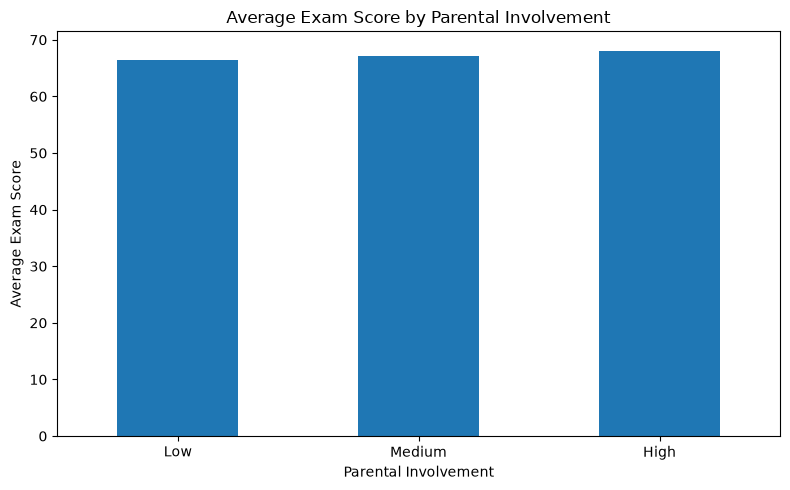

In [26]:
plt.figure(figsize=(8, 5))

parental_analysis.plot(kind="bar")

plt.title("Average Exam Score by Parental Involvement")
plt.xlabel("Parental Involvement")
plt.ylabel("Average Exam Score")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [27]:
resources_analysis = df.groupby("Access_to_Resources")["Exam_Score"].mean().sort_values()

resources_analysis

Access_to_Resources
Low       66.203351
Medium    67.134077
High      68.092152
Name: Exam_Score, dtype: float64

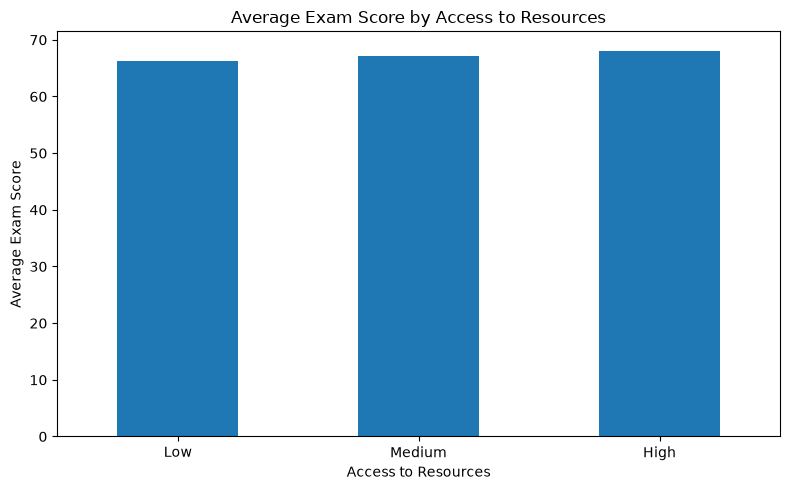

In [28]:
plt.figure(figsize=(8, 5))

resources_analysis.plot(kind="bar")

plt.title("Average Exam Score by Access to Resources")
plt.xlabel("Access to Resources")
plt.ylabel("Average Exam Score")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [29]:
tutoring_analysis = df.groupby("Tutoring_Sessions")["Exam_Score"].mean()

tutoring_analysis

Tutoring_Sessions
0    66.489755
1    66.980266
2    67.567010
3    67.894737
4    68.229236
5    69.058252
6    71.666667
7    69.857143
8    69.000000
Name: Exam_Score, dtype: float64

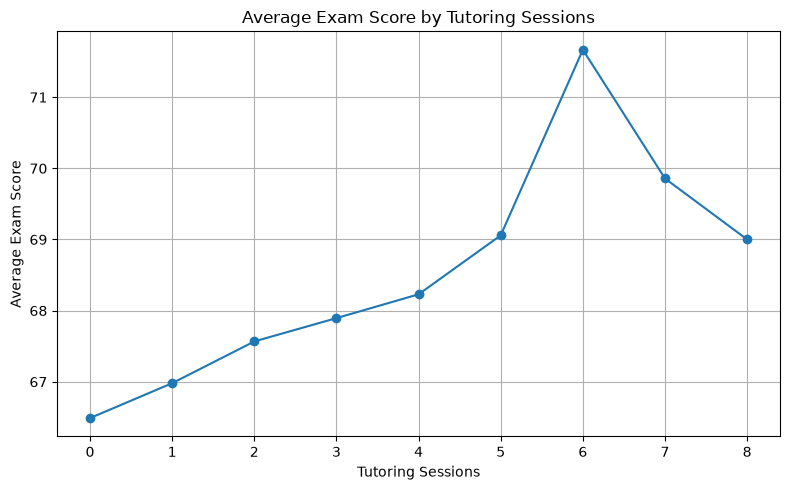

In [30]:
plt.figure(figsize=(8, 5))

tutoring_analysis.plot(kind="line", marker="o")

plt.title("Average Exam Score by Tutoring Sessions")
plt.xlabel("Tutoring Sessions")
plt.ylabel("Average Exam Score")
plt.grid(True)
plt.tight_layout()

plt.show()

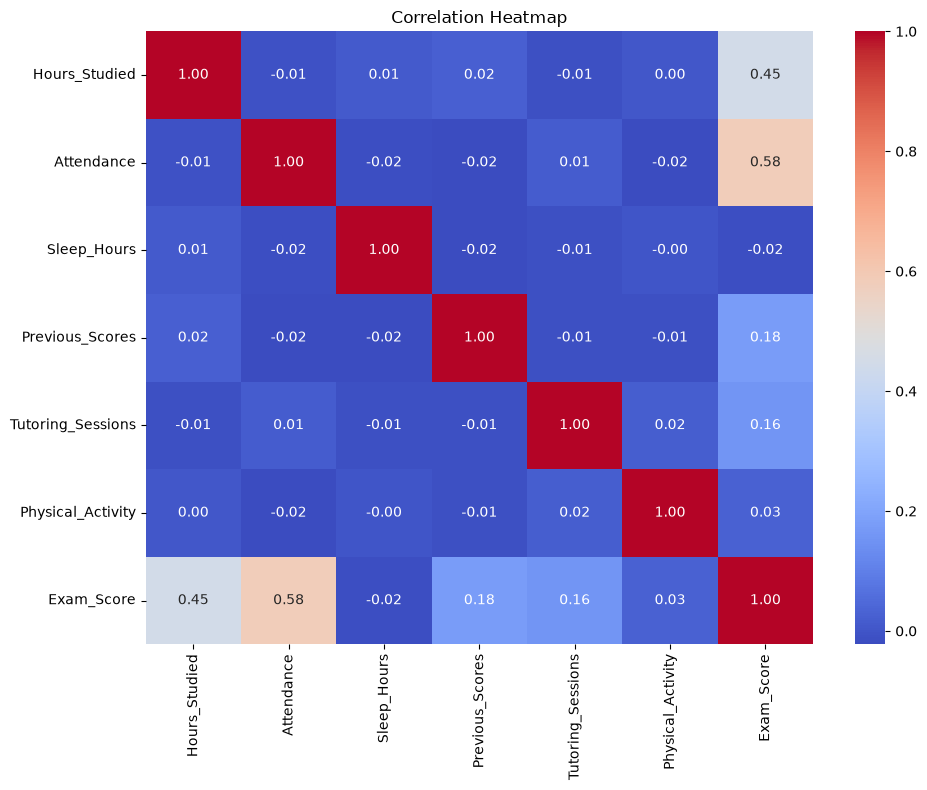

In [31]:
numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.show()

In [32]:
plt.savefig("../Visualization/correlation_heatmap.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

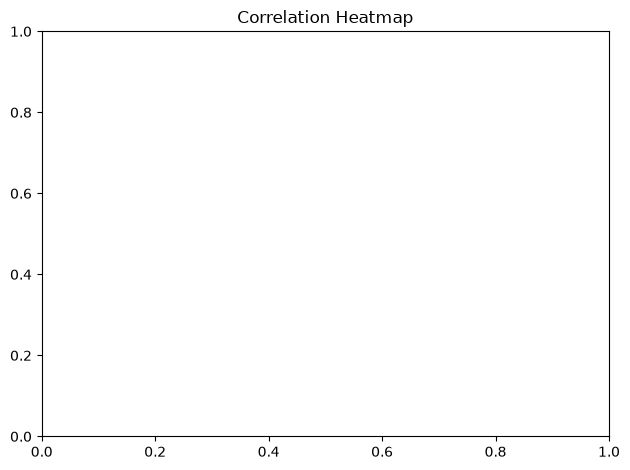

In [33]:
plt.title("Correlation Heatmap")
plt.tight_layout()

plt.savefig("../Visualization/correlation_heatmap.png", dpi=300, bbox_inches="tight")

plt.show()

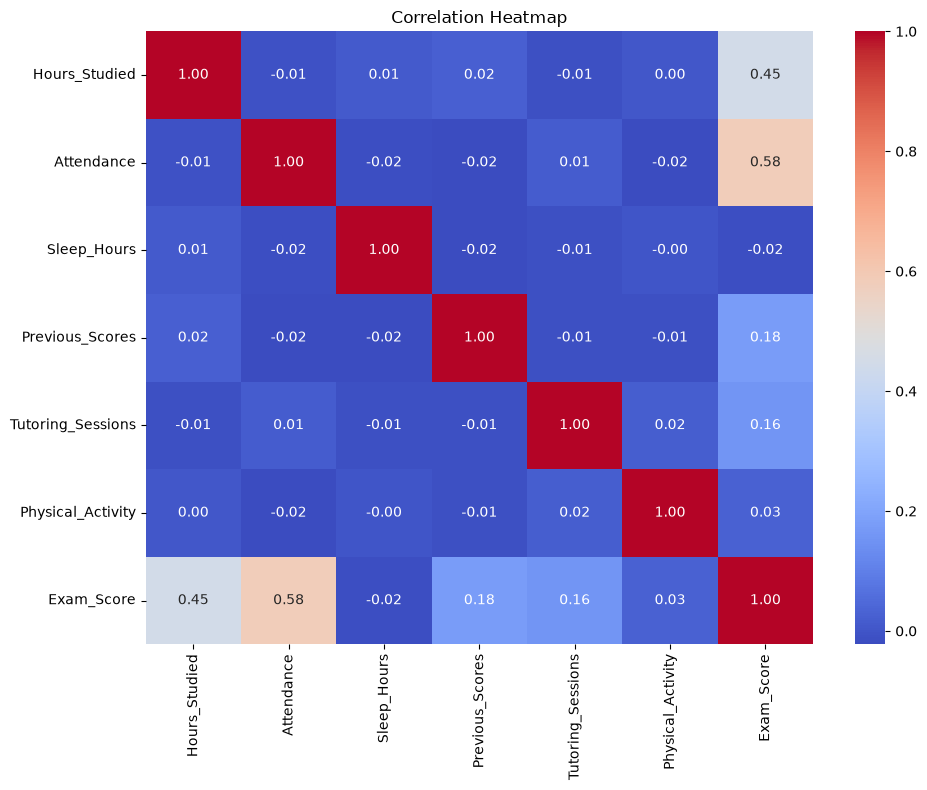

In [34]:
numeric_df = df.select_dtypes(include="number")

correlation = numeric_df.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()

plt.savefig(
    "../Visualization/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
X = df.drop("Exam_Score", axis=1)
y = df["Exam_Score"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (6607, 19)
Target shape: (6607,)


In [36]:
categorical_features = X.select_dtypes(include=["str"]).columns
numerical_features = X.select_dtypes(include=["number"]).columns

print("Categorical Features:")
print(categorical_features.tolist())

print("\nNumerical Features:")
print(numerical_features.tolist())

Categorical Features:
['Parental_Involvement', 'Access_to_Resources', 'Extracurricular_Activities', 'Motivation_Level', 'Internet_Access', 'Family_Income', 'Teacher_Quality', 'School_Type', 'Peer_Influence', 'Learning_Disabilities', 'Parental_Education_Level', 'Distance_from_Home', 'Gender']

Numerical Features:
['Hours_Studied', 'Attendance', 'Sleep_Hours', 'Previous_Scores', 'Tutoring_Sessions', 'Physical_Activity']


In [37]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

X_encoded = preprocessor.fit_transform(X)

print("Encoded feature shape:", X_encoded.shape)

ModuleNotFoundError: No module named 'sklearn'

In [38]:
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 2.9 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 3.7 MB/s  0:00:05m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn] [scikit-learn]

[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [39]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [40]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
        ("num", "passthrough", numerical_features)
    ]
)

X_encoded = preprocessor.fit_transform(X)

print("Encoded feature shape:", X_encoded.shape)

Encoded feature shape: (6607, 40)


In [41]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5285, 40)
Testing features: (1322, 40)
Training target: (5285,)
Testing target: (1322,)


In [42]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [43]:
y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print("First 10 predicted scores:")
print(y_pred[:10])

Predictions generated successfully!
First 10 predicted scores:
[64.49 66.03 70.41 65.75 67.07 66.43 71.36 67.13 69.49 69.69]


In [44]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model Performance:")
print("MAE:", mae)
print("RMSE:", rmse)
print("R² Score:", r2)

Model Performance:
MAE: 1.0914750378214826
RMSE: 2.165046022926956
R² Score: 0.6683834277944465


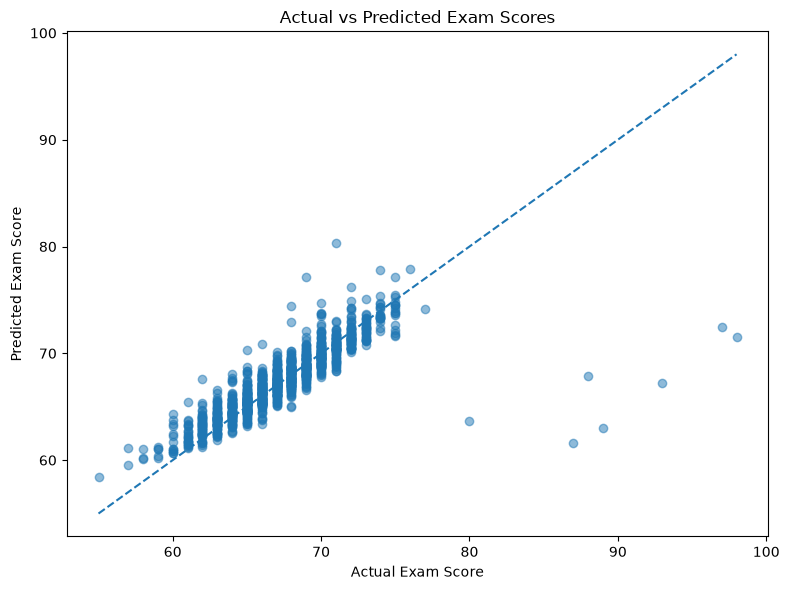

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Actual vs Predicted Exam Scores")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.tight_layout()
plt.show()

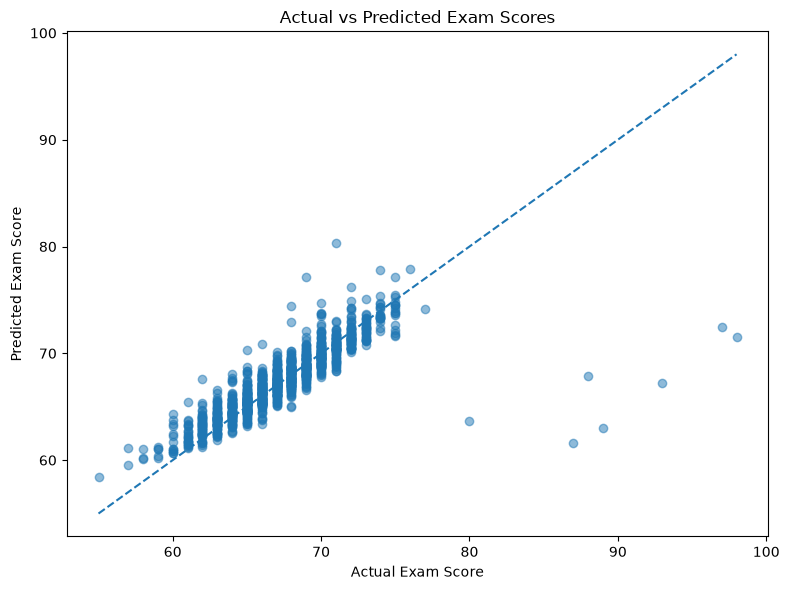

In [46]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual Exam Score")
plt.ylabel("Predicted Exam Score")
plt.title("Actual vs Predicted Exam Scores")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.tight_layout()

plt.savefig(
    "../Visualization/actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [47]:
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("Top 10 Important Features:")
print(importance_df.head(10))

Top 10 Important Features:
                           Feature  Importance
35                 num__Attendance    0.375181
34              num__Hours_Studied    0.238759
37            num__Previous_Scores    0.081595
38          num__Tutoring_Sessions    0.032494
39          num__Physical_Activity    0.025166
36                num__Sleep_Hours    0.024838
3    cat__Access_to_Resources_High    0.018907
0   cat__Parental_Involvement_High    0.017783
1    cat__Parental_Involvement_Low    0.013386
13         cat__Family_Income_High    0.010654


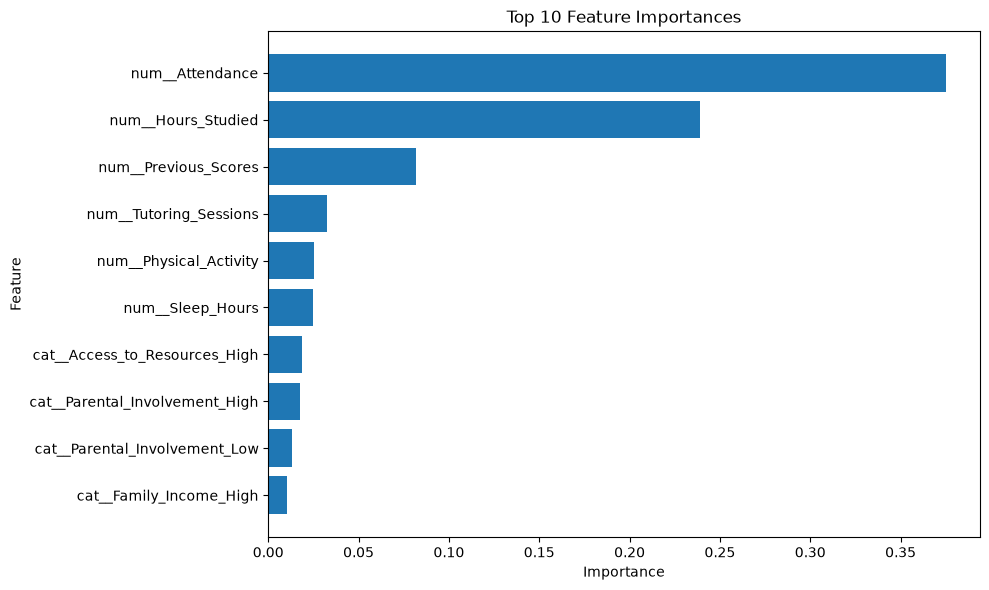

In [48]:
top_features = importance_df.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Feature Importances")

plt.tight_layout()

plt.savefig(
    "../Visualization/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

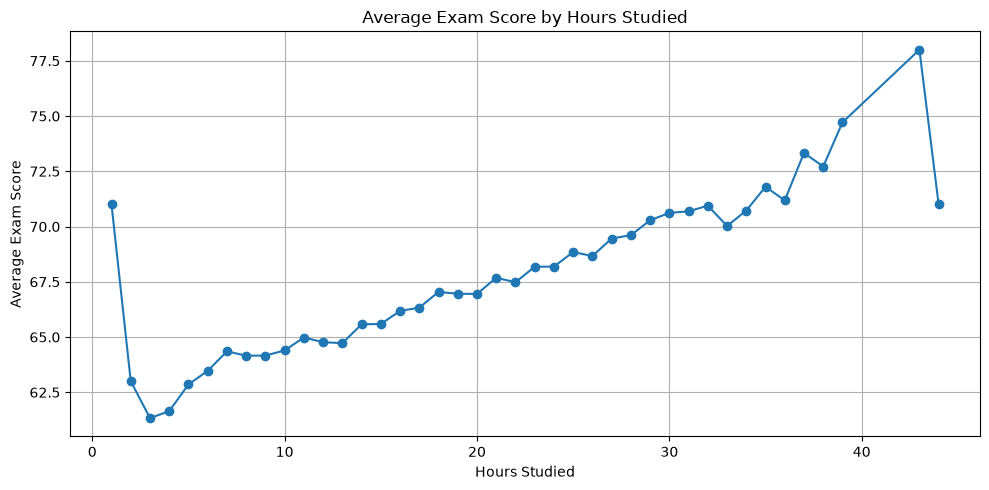

In [49]:
plt.figure(figsize=(10, 5))

study_hours_analysis.plot(
    kind="line",
    marker="o"
)

plt.title("Average Exam Score by Hours Studied")
plt.xlabel("Hours Studied")
plt.ylabel("Average Exam Score")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "../Visualization/study_hours_vs_score.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

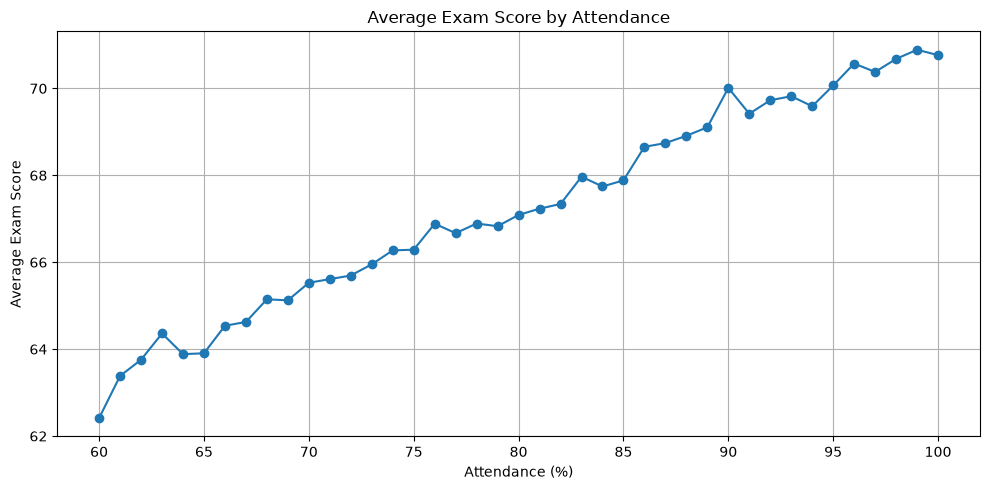

In [50]:
plt.figure(figsize=(10, 5))

attendance_analysis.plot(
    kind="line",
    marker="o"
)

plt.title("Average Exam Score by Attendance")
plt.xlabel("Attendance (%)")
plt.ylabel("Average Exam Score")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "../Visualization/attendance_vs_score.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

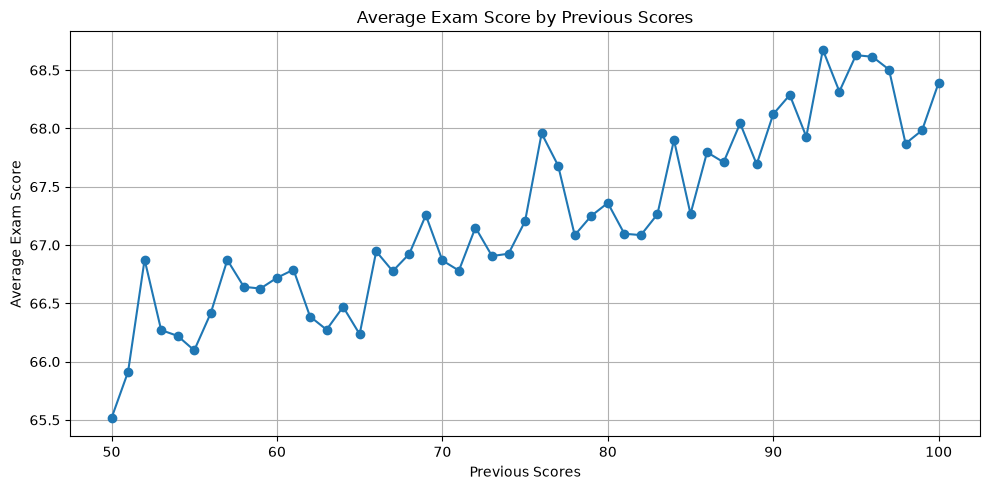

In [51]:
plt.figure(figsize=(10, 5))

previous_score_analysis.plot(
    kind="line",
    marker="o"
)

plt.title("Average Exam Score by Previous Scores")
plt.xlabel("Previous Scores")
plt.ylabel("Average Exam Score")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "../Visualization/previous_scores_vs_score.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

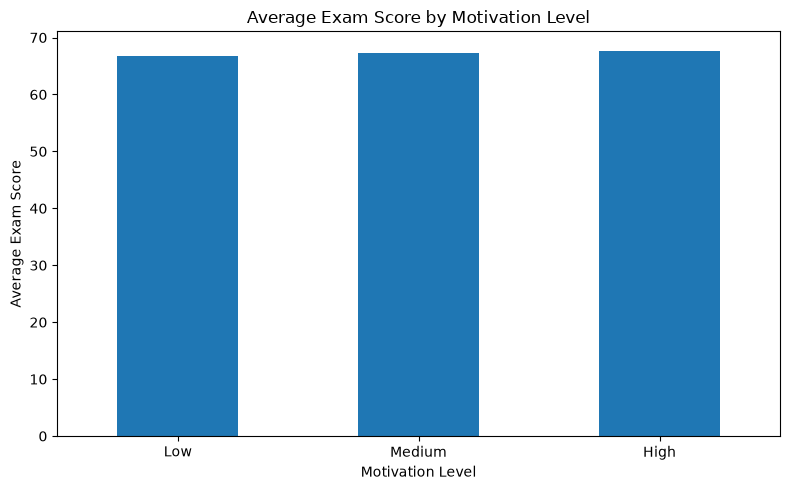

In [52]:
plt.figure(figsize=(8, 5))

motivation_analysis.plot(
    kind="bar"
)

plt.title("Average Exam Score by Motivation Level")
plt.xlabel("Motivation Level")
plt.ylabel("Average Exam Score")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../Visualization/motivation_vs_score.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

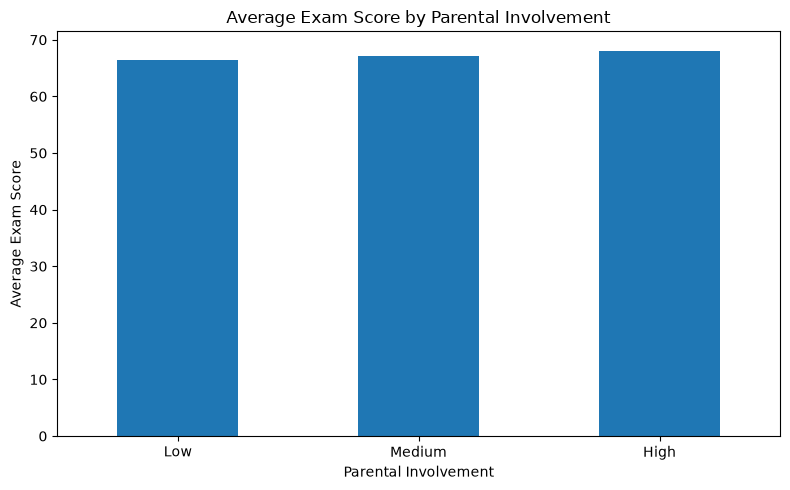

In [53]:
plt.figure(figsize=(8, 5))

parental_analysis.plot(
    kind="bar"
)

plt.title("Average Exam Score by Parental Involvement")
plt.xlabel("Parental Involvement")
plt.ylabel("Average Exam Score")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../Visualization/parental_involvement_vs_score.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

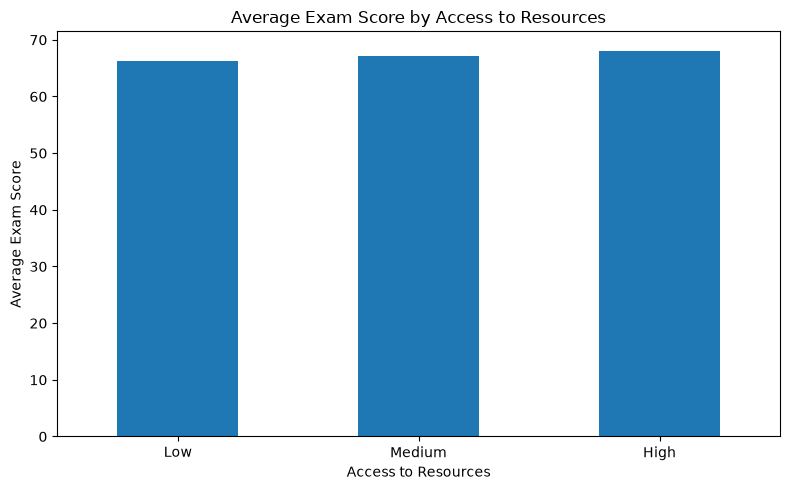

In [54]:
plt.figure(figsize=(8, 5))

resources_analysis.plot(
    kind="bar"
)

plt.title("Average Exam Score by Access to Resources")
plt.xlabel("Access to Resources")
plt.ylabel("Average Exam Score")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "../Visualization/resources_vs_score.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

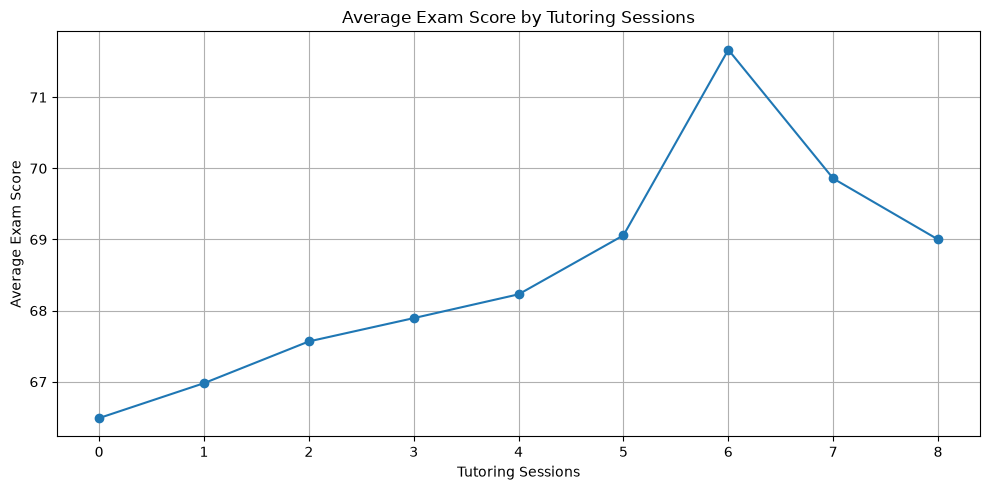

In [55]:
plt.figure(figsize=(10, 5))

tutoring_analysis.plot(
    kind="line",
    marker="o"
)

plt.title("Average Exam Score by Tutoring Sessions")
plt.xlabel("Tutoring Sessions")
plt.ylabel("Average Exam Score")
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "../Visualization/tutoring_vs_score.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()